/home/jupyter-r.yazdi/.local/lib/python3.10/site-packages/albumentations/check_version.py:49: UserWarning: Error fetching version info <urlopen error [Errno 101] Network is unreachable>
  data = fetch_version_info()


train: 349  val: 76  test: 75
Training Baseline TransUNet
epoch  1  started!  LR= [0.0001]
train_loss:  1.1441688266667454
val_loss:  0.9567136228084564
Validation_Dice Score = 0.858971726894
The best model saved...
Best validation dice= 0.8589717268943786  in epoch  1
Epoch finished in 6.211056126048788 seconds.

epoch  2  started!  LR= [0.0001]
train_loss:  0.9166809266263788
val_loss:  0.8901988983154296
Validation_Dice Score = 0.857305872440
Best validation dice= 0.8589717268943786  in epoch  1
Epoch finished in 5.06667735404335 seconds.

epoch  3  started!  LR= [0.0001]
train_loss:  0.7940390326760032
val_loss:  0.8026352405548096
Validation_Dice Score = 0.871011978388
The best model saved...
Best validation dice= 0.8710119783878326  in epoch  3
Epoch finished in 8.166246967855841 seconds.

epoch  4  started!  LR= [0.0001]
train_loss:  0.7182366035201333
val_loss:  0.6853797614574433
Validation_Dice Score = 0.902053028345
The best model saved...
Best validation dice= 0.90205302834

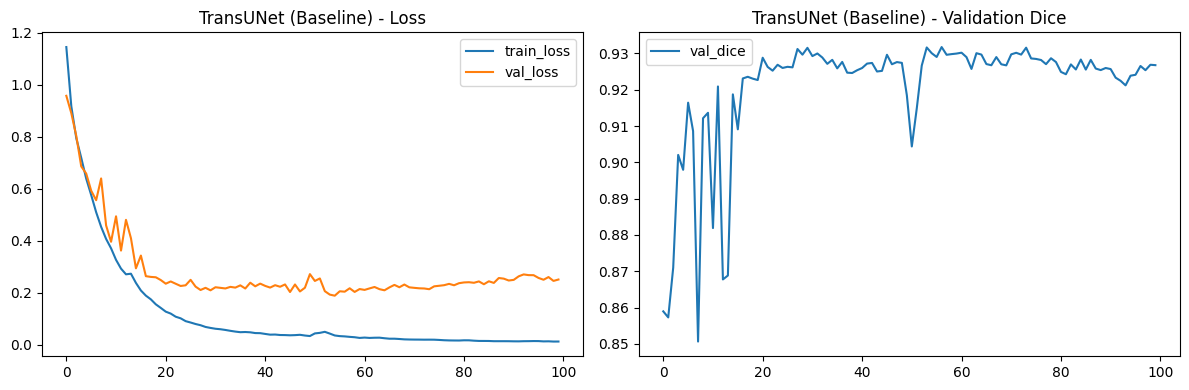

In [1]:
"""
Baseline TransUNet — training + test evaluation
"""

import os
from glob import glob
from time import perf_counter

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import StepLR

from TransUnet.vit_seg_modeling import VisionTransformer as ViT_seg
from TransUnet.vit_seg_modeling import CONFIGS as CONFIGS_ViT_seg


# ============================================================
# 0) Config
# ============================================================
ROOT = '/home/jupyter-r.yazdi/myproject/dti3d/0pycodes/UnetMaxsig/BUS_synthetic/'
config = {
    "lr": 1e-4,
    "batch_size": 8,
    "epochs": 100,
    "img_size": 256,
    "vit_name": "R50-ViT-B_16",
    "pretrained_path": "None"
}


# ============================================================
# 1) Dataset
# ============================================================
class mydataset(Dataset):
    def __init__(self, images_dir, masks_dir, transforms_img=None):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.transforms_img = transforms_img
        self.mask_names = glob(masks_dir + "*.png")

    def __len__(self):
        return len(self.mask_names)

    def __getitem__(self, index):
        mask_name = self.mask_names[index]
        mask = cv2.imread(mask_name, cv2.IMREAD_ANYDEPTH)
        mask = (mask - mask.min()) / (mask.max() - mask.min())
        mask = (mask > 0).astype(np.float32)
        mask = cv2.resize(mask, (256, 256), interpolation=cv2.INTER_AREA)

        imgn = mask_name.replace('/masks/', '/images/')
        image = cv2.imread(imgn, cv2.IMREAD_ANYDEPTH)
        image = (image - image.min()) / (image.max() - image.min()).astype(np.float32)
        image = cv2.resize(image, (256, 256), interpolation=cv2.INTER_AREA)

        if self.transforms_img is not None:
            transformed = self.transforms_img(image=image, mask=mask)
            image = transformed["image"]
            mask = transformed["mask"]

        return image, mask


def build_dataloaders(root, batch_size, img_size=256):
    resize = A.Resize(img_size, img_size)

    train_transform = A.Compose([resize, ToTensorV2()])
    val_transform = A.Compose([resize, ToTensorV2()])
    test_transform = A.Compose([resize, ToTensorV2()])

    train_ds = mydataset(root + 'dataset/train/images/', root + 'dataset/train/masks/', train_transform)
    val_ds = mydataset(root + 'dataset/val/images/', root + 'dataset/val/masks/', val_transform)
    test_ds = mydataset(root + 'dataset/test/images/', root + 'dataset/test/masks/', test_transform)

    print("train:", len(train_ds), " val:", len(val_ds), " test:", len(test_ds))

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)
    return train_loader, val_loader, test_loader


# ============================================================
# 2) Build model — Baseline TransUNet only
# ============================================================
def build_model(vit_name, img_size, num_classes, pretrained_path):
    config_vit = CONFIGS_ViT_seg[vit_name]
    config_vit.n_classes = num_classes
    config_vit.n_skip = 3
    if "R50" in vit_name:
        config_vit.patches.grid = (img_size // 16, img_size // 16)

    model = ViT_seg(config_vit, img_size=img_size, num_classes=num_classes)
    if pretrained_path and os.path.exists(pretrained_path):
        model.load_from(weights=np.load(pretrained_path))
    else:
        print("WARNING: pretrained_path not found — training from random init.")
    return model


# ============================================================
# 3) Loss / metrics
# ============================================================
def dice_loss(probs, targets, eps=1e-7):
    inter = (probs * targets).sum(dim=(2, 3))
    union = (probs + targets).sum(dim=(2, 3))
    return 1 - ((2 * inter + eps) / (union + eps)).mean()


def bce_dice_loss(logits, targets):
    probs = torch.sigmoid(logits)
    bce = F.binary_cross_entropy_with_logits(logits, targets)
    return bce + dice_loss(probs, targets)


@torch.no_grad()
def dice_score(logits, targets, eps=1e-7):
    preds = (torch.sigmoid(logits) > 0.5).float()
    inter = (preds * targets).sum()
    union = (preds + targets).sum()
    return float((2 * inter + eps) / (union + eps))


def prep_batch(inputs, mask, device):
    x = inputs.to(device).float()
    if x.dim() == 3:
        x = x.unsqueeze(1)
    if x.shape[1] == 1:
        x = x.repeat(1, 3, 1, 1)
    y = mask.to(device).unsqueeze(1).float()
    return x, y


# ============================================================
# 4) Train loop — with exact report format
# ============================================================
def train_one(model, train_loader, val_loader, device, epochs, lr,
              loss_fn=bce_dice_loss, tag="model", ckpt_path=None):
    model.to(device)
    optimizer = optim.AdamW(model.parameters(), lr=lr)
    scheduler = StepLR(optimizer, step_size=100, gamma=0.5)
    scaler = torch.amp.GradScaler('cuda') if device == "cuda" else None

    history = {"train_loss": [], "val_loss": [], "val_dice": []}
    best_dice = 0.0
    best_epoch = 0

    for epoch in range(epochs):
        t0 = perf_counter()
        current_lr = optimizer.param_groups[0]['lr']

        print(f"epoch  {epoch + 1}  started!  LR= [{current_lr}]")

        # ---- Training ----
        model.train()
        running = 0.0
        for inputs, mask in train_loader:
            x, y = prep_batch(inputs, mask, device)
            optimizer.zero_grad()
            if scaler is not None:
                with torch.autocast(device_type="cuda"):
                    logits = model(x)
                    loss = loss_fn(logits, y)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            else:
                logits = model(x)
                loss = loss_fn(logits, y)
                loss.backward()
                optimizer.step()
            running += loss.item()
        scheduler.step()
        train_loss = running / len(train_loader)

        # ---- Validation ----
        model.eval()
        val_running, dice_running = 0.0, 0.0
        with torch.no_grad():
            for inputs, mask in val_loader:
                x, y = prep_batch(inputs, mask, device)
                logits = model(x)
                val_running += loss_fn(logits, y).item()
                dice_running += dice_score(logits, y)

        val_loss = val_running / len(val_loader)
        val_dice = dice_running / len(val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_dice"].append(val_dice)

        # ---- Report (exact format) ----
        print(f"train_loss:  {train_loss}")
        print(f"val_loss:  {val_loss}")
        print(f"Validation_Dice Score = {val_dice:.12f}")

        if val_dice > best_dice:
            best_dice = val_dice
            best_epoch = epoch + 1
            if ckpt_path:
                torch.save(model.state_dict(), ckpt_path)
            print("The best model saved...")

        print(f"Best validation dice= {best_dice}  in epoch  {best_epoch}")
        elapsed = perf_counter() - t0
        print(f"Epoch finished in {elapsed} seconds.")
        print()

    return history, best_dice, best_epoch


# ============================================================
# 5) Test evaluation
# ============================================================
def evaluate_test(model, test_loader, device, loss_fn, ckpt_path):
    if os.path.exists(ckpt_path):
        model.load_state_dict(torch.load(ckpt_path))
    model.to(device)
    model.eval()

    test_loss = 0.0
    test_dice = 0.0
    with torch.no_grad():
        for inputs, mask in test_loader:
            x, y = prep_batch(inputs, mask, device)
            logits = model(x)
            test_loss += loss_fn(logits, y).item()
            test_dice += dice_score(logits, y)

    test_loss /= len(test_loader)
    test_dice /= len(test_loader)

    print("=" * 80)
    print("Test Dataset Evaluation")
    print("=" * 80)
    print(f"test_loss:  {test_loss}")
    print(f"Test_Dice Score = {test_dice:.12f}")
    print("=" * 80)

    return test_loss, test_dice


# ============================================================
# 6) Plot history
# ============================================================
def plot_history(history, title, save_path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="train_loss")
    axes[0].plot(history["val_loss"], label="val_loss")
    axes[0].set_title(f"{title} - Loss")
    axes[0].legend()

    axes[1].plot(history["val_dice"], label="val_dice")
    axes[1].set_title(f"{title} - Validation Dice")
    axes[1].legend()
    plt.tight_layout()
    plt.savefig(save_path)
    plt.show()


# ============================================================
# 7) Main
# ============================================================
if __name__ == "__main__":
    torch.manual_seed(42)
    device = "cuda" if torch.cuda.is_available() else "cpu"

    train_loader, val_loader, test_loader = build_dataloaders(
        ROOT, config["batch_size"], config["img_size"]
    )

    model = build_model(
        vit_name=config["vit_name"],
        img_size=config["img_size"],
        num_classes=1,
        pretrained_path=config["pretrained_path"],
    )

    ckpt_path = ROOT + "best-transunet.pt"

    print("=" * 80)
    print("Training Baseline TransUNet")
    print("=" * 80)

    history, best_dice, best_epoch = train_one(
        model, train_loader, val_loader, device,
        epochs=config["epochs"], lr=config["lr"],
        tag="TransUNet", ckpt_path=ckpt_path,
    )

    print()
    print(f"Training completed! Best validation dice = {best_dice} in epoch {best_epoch}")
    print()

    # ---- Test evaluation ----
    test_loss, test_dice = evaluate_test(
        model, test_loader, device, bce_dice_loss, ckpt_path
    )

    plot_history(history, "TransUNet (Baseline)", ROOT + "training_history_baseline.png")

In [ ]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")